In [ ]:
from google.colab import files

uploaded = files.upload()

Saving creditcard.csv.zip to creditcard.csv.zip


In [ ]:
import zipfile
import pandas as pd

# Get uploaded filename
zip_file = list(uploaded.keys())[0]

# Extract ZIP
with zipfile.ZipFile(zip_file, "r") as zip_ref:
    zip_ref.extractall("/content/data")

# Load CSV
df = pd.read_csv("/content/data/creditcard.csv")

print("Dataset Loaded Successfully!")
print("Dataset Shape:", df.shape)

print("\nFirst 5 rows:")
print(df.head())

print("\nClass Distribution:")
print(df["Class"].value_counts())

Dataset Loaded Successfully!
Dataset Shape: (284807, 31)

First 5 rows:
   Time        V1        V2        V3        V4        V5        V6        V7  \
0   0.0 -1.359807 -0.072781  2.536347  1.378155 -0.338321  0.462388  0.239599   
1   0.0  1.191857  0.266151  0.166480  0.448154  0.060018 -0.082361 -0.078803   
2   1.0 -1.358354 -1.340163  1.773209  0.379780 -0.503198  1.800499  0.791461   
3   1.0 -0.966272 -0.185226  1.792993 -0.863291 -0.010309  1.247203  0.237609   
4   2.0 -1.158233  0.877737  1.548718  0.403034 -0.407193  0.095921  0.592941   

         V8        V9  ...       V21       V22       V23       V24       V25  \
0  0.098698  0.363787  ... -0.018307  0.277838 -0.110474  0.066928  0.128539   
1  0.085102 -0.255425  ... -0.225775 -0.638672  0.101288 -0.339846  0.167170   
2  0.247676 -1.514654  ...  0.247998  0.771679  0.909412 -0.689281 -0.327642   
3  0.377436 -1.387024  ... -0.108300  0.005274 -0.190321 -1.175575  0.647376   
4 -0.270533  0.817739  ... -0.009431  0.7

In [ ]:
# Phase 1: Dataset Summary

total_transactions = len(df)
genuine_transactions = (df["Class"] == 0).sum()
fraud_transactions = (df["Class"] == 1).sum()
fraud_percentage = (fraud_transactions / total_transactions) * 100

dataset_summary = pd.DataFrame({
    "Metric": [
        "Total Transactions",
        "Genuine Transactions",
        "Fraudulent Transactions",
        "Fraud Percentage"
    ],
    "Value": [
        total_transactions,
        genuine_transactions,
        fraud_transactions,
        f"{fraud_percentage:.4f}%"
    ]
})

display(dataset_summary)

,Metric,Value
0,Total Transactions,284807
1,Genuine Transactions,284315
2,Fraudulent Transactions,492
3,Fraud Percentage,0.1727%


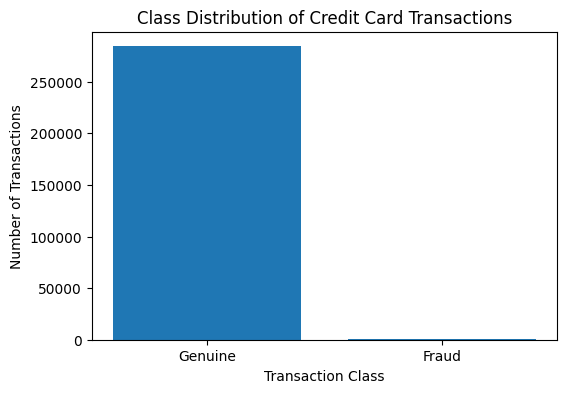

Average Genuine Transaction Amount: 88.29102242231328
Average Fraudulent Transaction Amount: 122.21132113821139


In [ ]:
# Phase 1: Class Distribution

import matplotlib.pyplot as plt

class_counts = df["Class"].value_counts().sort_index()

plt.figure(figsize=(6, 4))
plt.bar(["Genuine", "Fraud"], class_counts.values)
plt.xlabel("Transaction Class")
plt.ylabel("Number of Transactions")
plt.title("Class Distribution of Credit Card Transactions")
plt.show()

print("Average Genuine Transaction Amount:",
      df[df["Class"] == 0]["Amount"].mean())

print("Average Fraudulent Transaction Amount:",
      df[df["Class"] == 1]["Amount"].mean())

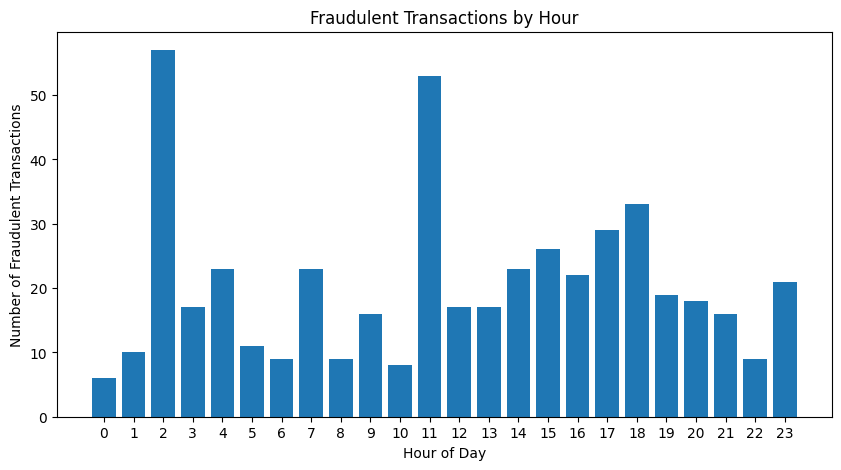

In [ ]:
# Phase 2: Fraud Occurrences by Hour

# Convert Time (seconds) into hour
df["Hour"] = (df["Time"] // 3600) % 24

# Count fraudulent transactions for each hour
fraud_by_hour = (
    df[df["Class"] == 1]
    .groupby("Hour")
    .size()
)

plt.figure(figsize=(10, 5))
plt.bar(fraud_by_hour.index, fraud_by_hour.values)
plt.xlabel("Hour of Day")
plt.ylabel("Number of Fraudulent Transactions")
plt.title("Fraudulent Transactions by Hour")
plt.xticks(range(24))
plt.show()

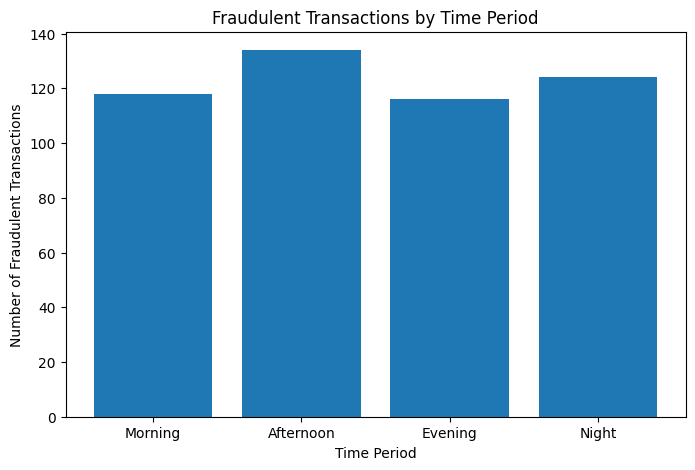

,Fraudulent Transactions
Time_Period,
Morning,118
Afternoon,134
Evening,116
Night,124


In [ ]:
# Phase 2: Fraud by Time Period

def time_period(hour):
    if 6 <= hour < 12:
        return "Morning"
    elif 12 <= hour < 18:
        return "Afternoon"
    elif 18 <= hour < 24:
        return "Evening"
    else:
        return "Night"

df["Time_Period"] = df["Hour"].apply(time_period)

fraud_by_period = (
    df[df["Class"] == 1]["Time_Period"]
    .value_counts()
    .reindex(["Morning", "Afternoon", "Evening", "Night"], fill_value=0)
)

plt.figure(figsize=(8, 5))
plt.bar(fraud_by_period.index, fraud_by_period.values)
plt.xlabel("Time Period")
plt.ylabel("Number of Fraudulent Transactions")
plt.title("Fraudulent Transactions by Time Period")
plt.show()

display(fraud_by_period.to_frame("Fraudulent Transactions"))

Average Genuine Transaction Amount: 88.29102242231328
Average Fraudulent Transaction Amount: 122.21132113821139


/tmp/ipykernel_1838/83175761.py:14: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


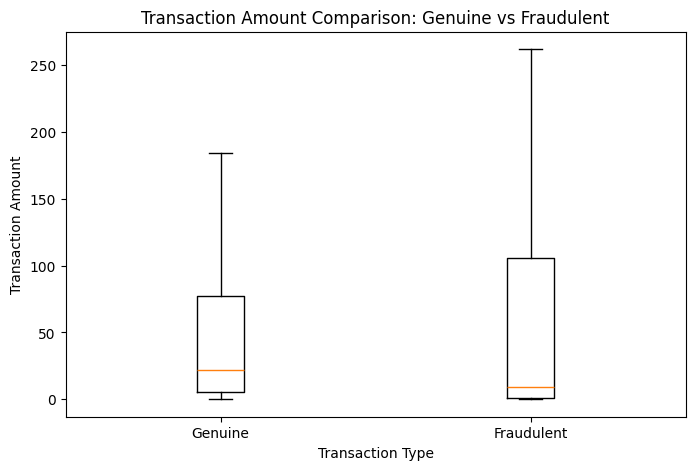

In [ ]:
# Phase 2: Spending Behavior Analysis

genuine_amount = df[df["Class"] == 0]["Amount"]
fraud_amount = df[df["Class"] == 1]["Amount"]

print("Average Genuine Transaction Amount:",
      genuine_amount.mean())

print("Average Fraudulent Transaction Amount:",
      fraud_amount.mean())

plt.figure(figsize=(8, 5))

plt.boxplot(
    [genuine_amount, fraud_amount],
    labels=["Genuine", "Fraudulent"],
    showfliers=False
)

plt.xlabel("Transaction Type")
plt.ylabel("Transaction Amount")
plt.title("Transaction Amount Comparison: Genuine vs Fraudulent")
plt.show()

Transactions within 5 minutes: 284806
Rapid fraudulent transactions: 492
Rapid genuine transactions: 284314


,Transaction Type,Rapid Transactions
0,Genuine,284314
1,Fraudulent,492


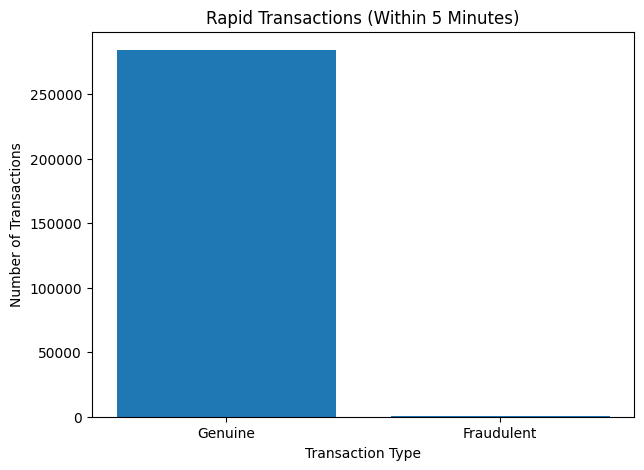

In [ ]:
# Phase 2: Rapid Transaction Analysis

# Sort transactions by time
df_sorted = df.sort_values("Time").copy()

# Difference between consecutive transactions
df_sorted["Time_Difference"] = df_sorted["Time"].diff()

# Transactions occurring within 5 minutes of the previous transaction
rapid_transactions = df_sorted[df_sorted["Time_Difference"] <= 300]

# Compare genuine and fraudulent rapid transactions
rapid_fraud = (rapid_transactions["Class"] == 1).sum()
rapid_genuine = (rapid_transactions["Class"] == 0).sum()

print("Transactions within 5 minutes:", len(rapid_transactions))
print("Rapid fraudulent transactions:", rapid_fraud)
print("Rapid genuine transactions:", rapid_genuine)

rapid_summary = pd.DataFrame({
    "Transaction Type": ["Genuine", "Fraudulent"],
    "Rapid Transactions": [rapid_genuine, rapid_fraud]
})

display(rapid_summary)

plt.figure(figsize=(7, 5))
plt.bar(
    rapid_summary["Transaction Type"],
    rapid_summary["Rapid Transactions"]
)
plt.xlabel("Transaction Type")
plt.ylabel("Number of Transactions")
plt.title("Rapid Transactions (Within 5 Minutes)")
plt.show()

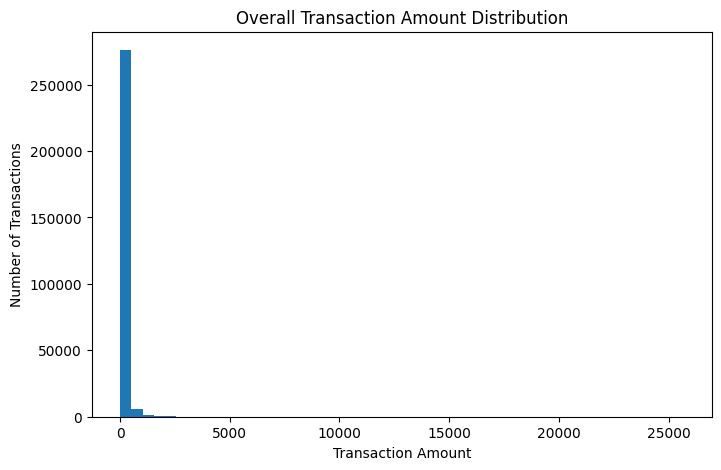

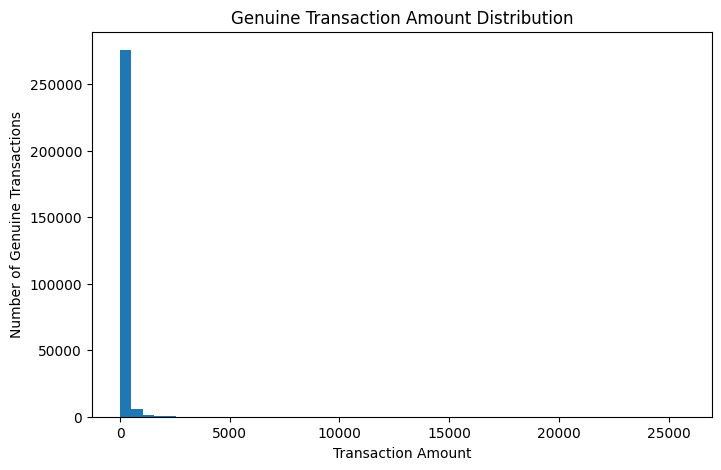

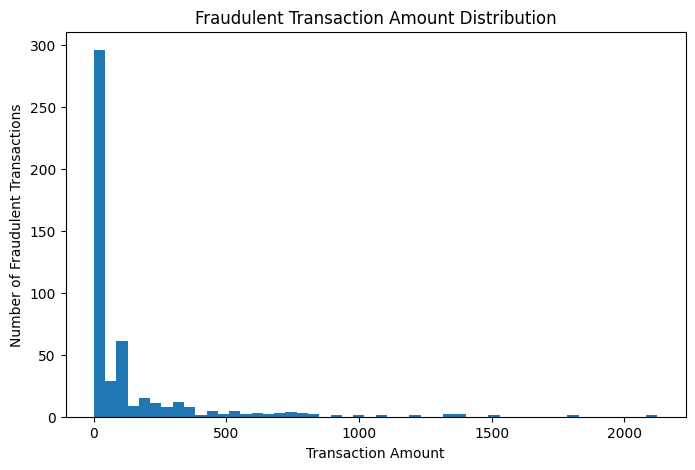

In [ ]:
# Phase 1: Transaction Amount Analysis

plt.figure(figsize=(8, 5))
plt.hist(df["Amount"], bins=50)
plt.xlabel("Transaction Amount")
plt.ylabel("Number of Transactions")
plt.title("Overall Transaction Amount Distribution")
plt.show()


plt.figure(figsize=(8, 5))
plt.hist(df[df["Class"] == 0]["Amount"], bins=50)
plt.xlabel("Transaction Amount")
plt.ylabel("Number of Genuine Transactions")
plt.title("Genuine Transaction Amount Distribution")
plt.show()


plt.figure(figsize=(8, 5))
plt.hist(df[df["Class"] == 1]["Amount"], bins=50)
plt.xlabel("Transaction Amount")
plt.ylabel("Number of Fraudulent Transactions")
plt.title("Fraudulent Transaction Amount Distribution")
plt.show()

In [ ]:
# Remove analysis-only categorical column before ML preprocessing
df = df.drop(columns=["Time_Period"], errors="ignore")

In [ ]:
# Processing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import numpy as np

# Remove duplicate records
df = df.drop_duplicates()

print("Shape after removing duplicates:", df.shape)

# Separate input and output
X = df.drop("Class", axis=1)
y = df["Class"]

# Feature Engineering
X["Amount_log"] = np.log1p(X["Amount"].abs())

# Split dataset FIRST
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Scale Time and Amount AFTER splitting
scaler = StandardScaler()

X_train[["Time", "Amount"]] = scaler.fit_transform(
    X_train[["Time", "Amount"]]
)

X_test[["Time", "Amount"]] = scaler.transform(
    X_test[["Time", "Amount"]]
)

print("\nTraining data:", X_train.shape)
print("Testing data:", X_test.shape)

Shape after removing duplicates: (283726, 32)

Training data: (226980, 32)
Testing data: (56746, 32)


In [ ]:
# Random forest
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Create Random Forest
rf_model = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

# Train
rf_model.fit(X_train, y_train)

# Predict
rf_pred = rf_model.predict(X_test)

# Calculate metrics
rf_accuracy = accuracy_score(y_test, rf_pred)
rf_precision = precision_score(y_test, rf_pred)
rf_recall = recall_score(y_test, rf_pred)
rf_f1 = f1_score(y_test, rf_pred)

print("========== RANDOM FOREST ==========")
print("Accuracy :", rf_accuracy)
print("Precision:", rf_precision)
print("Recall   :", rf_recall)
print("F1 Score :", rf_f1)

print("\nClassification Report:")
print(classification_report(y_test, rf_pred))

print("Confusion Matrix:")
print(confusion_matrix(y_test, rf_pred))

========== RANDOM FOREST ==========
Accuracy : 0.9994360836006062
Precision: 0.9701492537313433
Recall   : 0.6842105263157895
F1 Score : 0.8024691358024691

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.97      0.68      0.80        95

    accuracy                           1.00     56746
   macro avg       0.98      0.84      0.90     56746
weighted avg       1.00      1.00      1.00     56746

Confusion Matrix:
[[56649     2]
 [   30    65]]


In [ ]:
#XGBClassifier
from xgboost import XGBClassifier

# Calculate class imbalance
scale_pos = (
    y_train.value_counts()[0] /
    y_train.value_counts()[1]
)

# Create XGBoost
xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    scale_pos_weight=scale_pos,
    eval_metric="logloss",
    random_state=42
)

# Train
xgb_model.fit(X_train, y_train)

# Predict
xgb_pred = xgb_model.predict(X_test)

# Metrics
xgb_accuracy = accuracy_score(y_test, xgb_pred)
xgb_precision = precision_score(y_test, xgb_pred)
xgb_recall = recall_score(y_test, xgb_pred)
xgb_f1 = f1_score(y_test, xgb_pred)

print("========== XGBOOST ==========")
print("Accuracy :", xgb_accuracy)
print("Precision:", xgb_precision)
print("Recall   :", xgb_recall)
print("F1 Score :", xgb_f1)

print("\nClassification Report:")
print(classification_report(y_test, xgb_pred))

print("Confusion Matrix:")
print(confusion_matrix(y_test, xgb_pred))

========== XGBOOST ==========
Accuracy : 0.9993303492757198
Precision: 0.8064516129032258
Recall   : 0.7894736842105263
F1 Score : 0.7978723404255319

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.81      0.79      0.80        95

    accuracy                           1.00     56746
   macro avg       0.90      0.89      0.90     56746
weighted avg       1.00      1.00      1.00     56746

Confusion Matrix:
[[56633    18]
 [   20    75]]


In [ ]:
#LGBMClassifier

!pip install lightgbm -q
from lightgbm import LGBMClassifier

# Create LightGBM
lgbm_model = LGBMClassifier(
    n_estimators=100,
    learning_rate=0.1,
    num_leaves=31,
    class_weight="balanced",
    random_state=42,
    verbosity=-1
)

# Train
lgbm_model.fit(X_train, y_train)

# Predict
lgbm_pred = lgbm_model.predict(X_test)

# Metrics
lgbm_accuracy = accuracy_score(y_test, lgbm_pred)
lgbm_precision = precision_score(y_test, lgbm_pred)
lgbm_recall = recall_score(y_test, lgbm_pred)
lgbm_f1 = f1_score(y_test, lgbm_pred)

print("========== LIGHTGBM ==========")
print("Accuracy :", lgbm_accuracy)
print("Precision:", lgbm_precision)
print("Recall   :", lgbm_recall)
print("F1 Score :", lgbm_f1)

print("\nClassification Report:")
print(classification_report(y_test, lgbm_pred))

print("Confusion Matrix:")
print(confusion_matrix(y_test, lgbm_pred))

========== LIGHTGBM ==========
Accuracy : 0.9993303492757198
Precision: 0.8202247191011236
Recall   : 0.7684210526315789
F1 Score : 0.7934782608695652

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.82      0.77      0.79        95

    accuracy                           1.00     56746
   macro avg       0.91      0.88      0.90     56746
weighted avg       1.00      1.00      1.00     56746

Confusion Matrix:
[[56635    16]
 [   22    73]]


In [ ]:
# ============================================================
# HYBRID STACKING ENSEMBLE
# ============================================================

from sklearn.ensemble import StackingClassifier
from sklearn.linear_model import LogisticRegression

stacking_model = StackingClassifier(
    estimators=[
        ("rf", rf_model),
        ("xgb", xgb_model),
        ("lgbm", lgbm_model)
    ],
    final_estimator=LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ),
    stack_method="predict_proba",
    n_jobs=-1
)

stacking_model.fit(X_train, y_train)

# Predictions
stack_pred = stacking_model.predict(X_test)
stack_prob = stacking_model.predict_proba(X_test)[:, 1]

print("========== HYBRID STACKING ENSEMBLE ==========")

========== HYBRID STACKING ENSEMBLE ==========


In [ ]:
# Hybrid Stacking Ensemble Evaluation

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)

stack_accuracy = accuracy_score(y_test, stack_pred)
stack_precision = precision_score(y_test, stack_pred)
stack_recall = recall_score(y_test, stack_pred)
stack_f1 = f1_score(y_test, stack_pred)
stack_roc_auc = roc_auc_score(y_test, stack_prob)
stack_pr_auc = average_precision_score(y_test, stack_prob)

print("========== HYBRID STACKING ENSEMBLE ==========")
print("Accuracy :", stack_accuracy)
print("Precision:", stack_precision)
print("Recall   :", stack_recall)
print("F1 Score :", stack_f1)
print("ROC-AUC  :", stack_roc_auc)
print("PR-AUC   :", stack_pr_auc)

print("\nClassification Report:")
print(classification_report(y_test, stack_pred))

print("Confusion Matrix:")
print(confusion_matrix(y_test, stack_pred))

========== HYBRID STACKING ENSEMBLE ==========
Accuracy : 0.9965636344411941
Precision: 0.3062015503875969
Recall   : 0.8315789473684211
F1 Score : 0.4475920679886686
ROC-AUC  : 0.9748346524286745
PR-AUC   : 0.8023816555732933

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.31      0.83      0.45        95

    accuracy                           1.00     56746
   macro avg       0.65      0.91      0.72     56746
weighted avg       1.00      1.00      1.00     56746

Confusion Matrix:
[[56472   179]
 [   16    79]]


In [ ]:
# ============================================================
# FINE-GRAINED THRESHOLD OPTIMIZATION
# ============================================================

thresholds = np.arange(0.90, 1.00, 0.01)

threshold_results = []

for threshold in thresholds:
    threshold_pred = (stack_prob >= threshold).astype(int)

    precision = precision_score(
        y_test, threshold_pred, zero_division=0
    )
    recall = recall_score(
        y_test, threshold_pred, zero_division=0
    )
    f1 = f1_score(
        y_test, threshold_pred, zero_division=0
    )

    threshold_results.append({
        "Threshold": round(threshold, 2),
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

threshold_df = pd.DataFrame(threshold_results)

print("========== FINE-GRAINED THRESHOLD OPTIMIZATION ==========")
print(threshold_df.to_string(index=False))

========== FINE-GRAINED THRESHOLD OPTIMIZATION ==========
 Threshold  Precision   Recall  F1 Score
      0.90   0.461538 0.821053  0.590909
      0.91   0.464286 0.821053  0.593156
      0.92   0.472727 0.821053  0.600000
      0.93   0.481481 0.821053  0.607004
      0.94   0.490566 0.821053  0.614173
      0.95   0.490566 0.821053  0.614173
      0.96   0.506494 0.821053  0.626506
      0.97   0.513158 0.821053  0.631579
      0.98   0.557143 0.821053  0.663830
      0.99   0.569343 0.821053  0.672414


In [ ]:
# ============================================================
# SELECT BEST THRESHOLD
# ============================================================

best_threshold_row = threshold_df.loc[
    threshold_df["F1 Score"].idxmax()
]

best_threshold = best_threshold_row["Threshold"]
best_precision = best_threshold_row["Precision"]
best_recall = best_threshold_row["Recall"]
best_f1 = best_threshold_row["F1 Score"]

print("========== BEST THRESHOLD ==========")
print("Best Threshold :", best_threshold)
print("Precision      :", best_precision)
print("Recall         :", best_recall)
print("F1 Score       :", best_f1)

========== BEST THRESHOLD ==========
Best Threshold : 0.99
Precision      : 0.5693430656934306
Recall         : 0.8210526315789474
F1 Score       : 0.6724137931034483


In [ ]:
# ============================================================
# COMPARE ALL MODELS
# ============================================================

results = pd.DataFrame({

    "Model": [
        "Random Forest",
        "XGBoost",
        "LightGBM",
        "Stacking Ensemble (0.99)"
    ],

    "Accuracy": [
        rf_accuracy,
        xgb_accuracy,
        lgbm_accuracy,
        accuracy_score(y_test, (stack_prob >= best_threshold).astype(int))
    ],

    "Precision": [
        rf_precision,
        xgb_precision,
        lgbm_precision,
        best_precision
    ],

    "Recall": [
        rf_recall,
        xgb_recall,
        lgbm_recall,
        best_recall
    ],

    "F1 Score": [
        rf_f1,
        xgb_f1,
        lgbm_f1,
        best_f1
    ],

    "ROC-AUC": [
        roc_auc_score(y_test, rf_model.predict_proba(X_test)[:, 1]),
        roc_auc_score(y_test, xgb_model.predict_proba(X_test)[:, 1]),
        roc_auc_score(y_test, lgbm_model.predict_proba(X_test)[:, 1]),
        stack_roc_auc
    ],

    "PR-AUC": [
        average_precision_score(y_test, rf_model.predict_proba(X_test)[:, 1]),
        average_precision_score(y_test, xgb_model.predict_proba(X_test)[:, 1]),
        average_precision_score(y_test, lgbm_model.predict_proba(X_test)[:, 1]),
        stack_pr_auc
    ]
})

print("========== MODEL COMPARISON ==========")
print(results.round(4))

========== MODEL COMPARISON ==========
                      Model  Accuracy  Precision  Recall  F1 Score  ROC-AUC  \
0             Random Forest    0.9994     0.9701  0.6842    0.8025   0.9403   
1                   XGBoost    0.9993     0.8065  0.7895    0.7979   0.9700   
2                  LightGBM    0.9993     0.8202  0.7684    0.7935   0.9698   
3  Stacking Ensemble (0.99)    0.9987     0.5693  0.8211    0.6724   0.9748   

   PR-AUC  
0  0.8015  
1  0.8031  
2  0.7966  
3  0.8024  


In [ ]:
# ============================================================
# BEST MODEL BASED ON F1 SCORE
# ============================================================

best_index = results["F1 Score"].idxmax()

best_model_name = results.loc[
    best_index, "Model"
]

print("Best Model:", best_model_name)

Best Model: Random Forest


In [ ]:
# ============================================================
# SELECT BEST MODEL
# ============================================================

if best_model_name == "Random Forest":

    best_model = rf_model
    best_pred = rf_pred

elif best_model_name == "XGBoost":

    best_model = xgb_model
    best_pred = xgb_pred

elif best_model_name == "LightGBM":

    best_model = lgbm_model
    best_pred = lgbm_pred

elif best_model_name == "Stacking Ensemble (0.99)":

    best_model = stacking_model
    best_pred = final_stack_pred

print("Selected Model:", best_model_name)

Selected Model: Random Forest


In [ ]:
# shap analysis
!pip install shap -q

In [ ]:
import shap

# Use only a small sample for fast SHAP analysis
X_test_sample = X_test.sample(n=500, random_state=42)

# Create SHAP explainer
explainer = shap.TreeExplainer(best_model)

# Calculate SHAP values
shap_values = explainer(X_test_sample)

print("SHAP analysis completed!")

SHAP analysis completed!


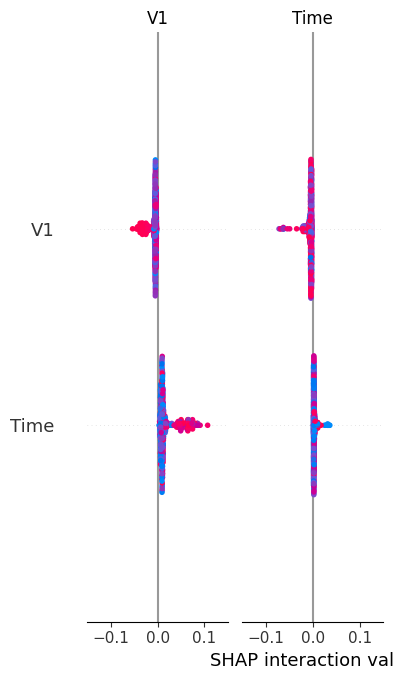

In [ ]:
shap.summary_plot(
    shap_values,
    X_test_sample
)

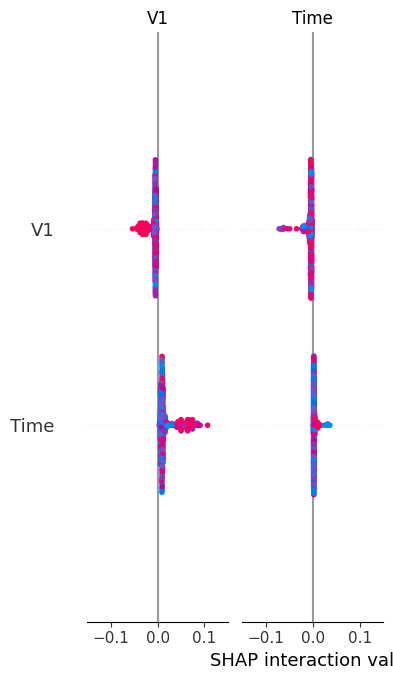

In [ ]:
# Feature
shap.summary_plot(
    shap_values,
    X_test_sample,
    plot_type="bar"
)

In [ ]:
# ============================================================
# TOP 10 IMPORTANT FEATURES USING SHAP
# ============================================================

# Handle different SHAP output formats
if len(shap_values.values.shape) == 3:
    # Multi-class output: select positive/fraud class
    shap_array = shap_values.values[:, :, 1]
else:
    # Binary/single-output format
    shap_array = shap_values.values

shap_importance = pd.DataFrame({
    "Feature": X_test_sample.columns,
    "SHAP Importance": np.abs(shap_array).mean(axis=0)
})

shap_importance = shap_importance.sort_values(
    "SHAP Importance",
    ascending=False
)

print("========== TOP 10 IMPORTANT FEATURES ==========")
print(shap_importance.head(10).to_string(index=False))

========== TOP 10 IMPORTANT FEATURES ==========
Feature  SHAP Importance
    V12         0.077662
    V14         0.070654
     V3         0.053957
     V4         0.049878
    V11         0.043463
    V10         0.040752
    V17         0.026033
    V16         0.021339
     V1         0.010893
     V7         0.010819


In [ ]:
# ============================================================
# FRAUD PATTERN DISCOVERY
# ============================================================

# Fraud probability from the selected best model
fraud_probability = best_model.predict_proba(X_test)[:, 1]

# Create analysis dataframe
fraud_analysis = X_test.copy()

fraud_analysis["Actual_Class"] = y_test.values

fraud_analysis["Fraud_Probability"] = fraud_probability

fraud_analysis["Prediction"] = best_pred

print("========== FRAUD ANALYSIS ==========")
print(fraud_analysis.head())

========== FRAUD ANALYSIS ==========
            Time        V1        V2        V3        V4        V5        V6  \
86568  -0.707761  1.228821 -0.063408  0.274145  0.647465 -0.048135  0.372073   
251557  1.273872 -0.203154  1.176678 -0.759595 -0.518472  0.629649 -0.721675   
20232  -1.348111 -1.672836  1.401297  1.503940  2.175491  0.699791  1.062139   
68952  -0.878056  0.819379 -1.124913  0.515025  0.513945 -1.009048  0.488484   
191852  0.727104  2.009701  0.105635 -1.752759  0.588312  0.374801 -0.637884   

              V7        V8        V9  ...       V25       V26       V27  \
86568  -0.224231  0.079939  0.640759  ...  0.598550  0.491409  0.002989   
251557  0.638893  0.243377 -0.157488  ... -0.710906 -0.234510  0.379640   
20232   1.114364 -0.535822 -0.252983  ... -0.155456 -0.062383  0.007777   
68952  -0.580672  0.187686 -0.999142  ...  0.238538 -0.289454  0.038214   
191852  0.009260 -0.129487  0.492619  ...  0.111522  0.642944 -0.036998   

             V28    Amount  Hou

In [ ]:
# ============================================================
# FRAUD RISK CLASSIFICATION FRAMEWORK
# ============================================================

def risk_level(probability):

    if probability >= 0.80:
        return "HIGH RISK"

    elif probability >= 0.50:
        return "MEDIUM RISK"

    else:
        return "LOW RISK"

In [ ]:
# ============================================================
# APPLY RISK LEVELS
# ============================================================

fraud_analysis["Risk_Level"] = fraud_analysis[
    "Fraud_Probability"
].apply(risk_level)

print("Risk levels added successfully!")
print(fraud_analysis["Risk_Level"].value_counts())

Risk levels added successfully!
Risk_Level
LOW RISK       56678
HIGH RISK         53
MEDIUM RISK       15
Name: count, dtype: int64


In [ ]:
# ============================================================
# FRAUD RISK + PREVENTION FRAMEWORK
# ============================================================

# Make sure fraud_analysis exists
fraud_analysis = X_test.copy()

# Fraud probability from selected best model
fraud_analysis["Fraud_Probability"] = (
    best_model.predict_proba(X_test)[:, 1]
)

# Actual class
fraud_analysis["Actual_Class"] = y_test.values

# Use the selected model prediction
fraud_analysis["Prediction"] = best_pred

# Risk classification
def risk_level(probability):
    if probability >= 0.80:
        return "HIGH RISK"
    elif probability >= 0.50:
        return "MEDIUM RISK"
    else:
        return "LOW RISK"

fraud_analysis["Risk_Level"] = (
    fraud_analysis["Fraud_Probability"].apply(risk_level)
)

# Prevention action
def prevention_action(risk):
    if risk == "HIGH RISK":
        return "BLOCK + ALERT"
    elif risk == "MEDIUM RISK":
        return "MANUAL REVIEW"
    else:
        return "APPROVE"

fraud_analysis["Prevention_Action"] = (
    fraud_analysis["Risk_Level"].apply(prevention_action)
)

print("========== FRAUD RESPONSE FRAMEWORK ==========")

print(
    fraud_analysis[
        [
            "Fraud_Probability",
            "Prediction",
            "Risk_Level",
            "Prevention_Action"
        ]
    ].head(10)
)

print("\n========== RISK DISTRIBUTION ==========")
print(fraud_analysis["Risk_Level"].value_counts())

========== FRAUD RESPONSE FRAMEWORK ==========
        Fraud_Probability  Prediction Risk_Level Prevention_Action
86568                 0.0           0   LOW RISK           APPROVE
251557                0.0           0   LOW RISK           APPROVE
20232                 0.0           0   LOW RISK           APPROVE
68952                 0.0           0   LOW RISK           APPROVE
191852                0.0           0   LOW RISK           APPROVE
94289                 0.0           0   LOW RISK           APPROVE
16245                 0.0           0   LOW RISK           APPROVE
16056                 0.0           0   LOW RISK           APPROVE
158543                0.0           0   LOW RISK           APPROVE
212344                0.0           0   LOW RISK           APPROVE

========== RISK DISTRIBUTION ==========
Risk_Level
LOW RISK       56678
HIGH RISK         53
MEDIUM RISK       15
Name: count, dtype: int64


In [ ]:
# ============================================================
# FINAL STACKING PREDICTIONS
# ============================================================

final_stack_pred = (
    stack_prob >= best_threshold
).astype(int)

print("Final threshold:", best_threshold)
print("Final stacking predictions created!")

Final threshold: 0.99
Final stacking predictions created!



Random Forest


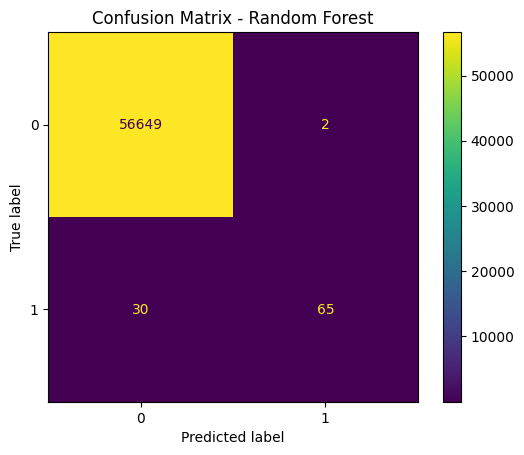


XGBoost


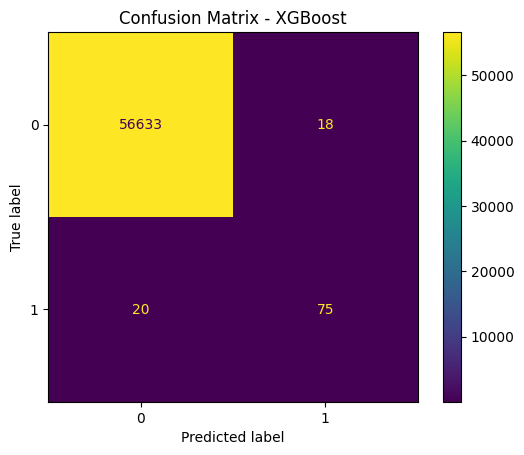


LightGBM


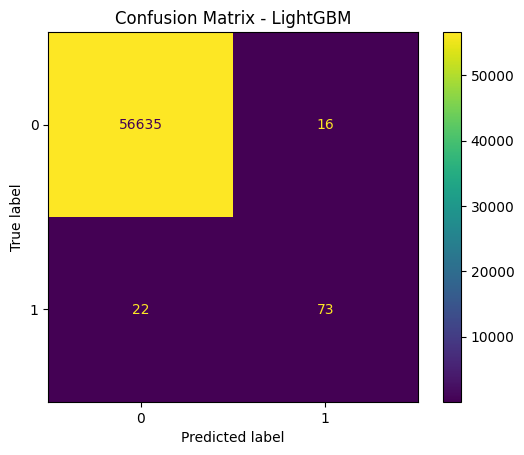


Stacking Ensemble


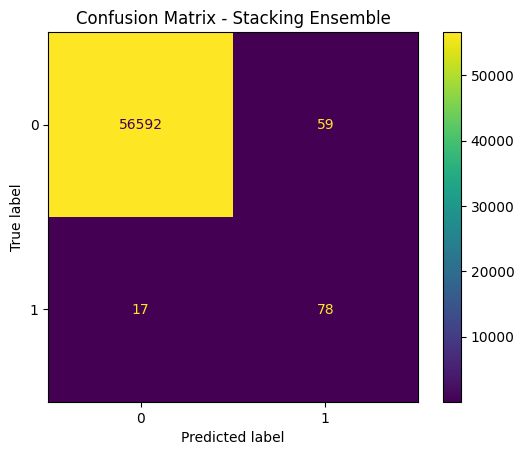

In [ ]:
# ============================================================
# CONFUSION MATRICES
# ============================================================

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

models = {
    "Random Forest": (rf_model, rf_pred),
    "XGBoost": (xgb_model, xgb_pred),
    "LightGBM": (lgbm_model, lgbm_pred),
    "Stacking Ensemble": (
        stacking_model,
        final_stack_pred
    )
}

for name, (model, predictions) in models.items():

    print(f"\n{name}")

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predictions
    )

    plt.title(f"Confusion Matrix - {name}")
    plt.show()

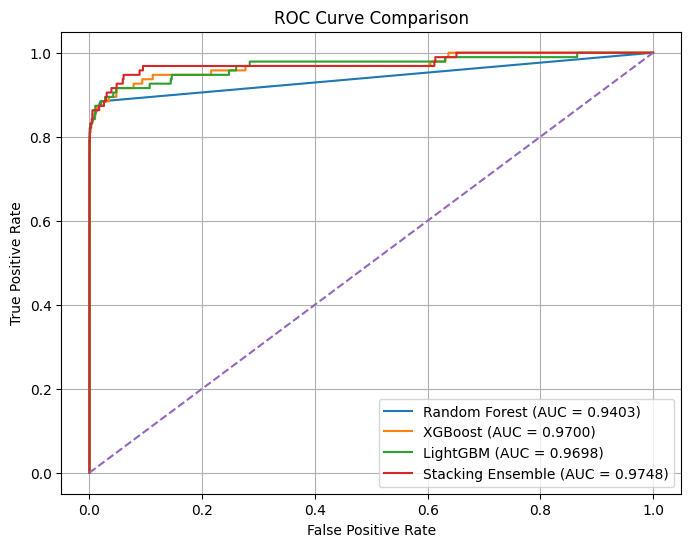

In [ ]:
# ============================================================
# ROC CURVE COMPARISON
# ============================================================

from sklearn.metrics import roc_curve, auc

rf_prob = rf_model.predict_proba(X_test)[:, 1]
xgb_prob = xgb_model.predict_proba(X_test)[:, 1]
lgbm_prob = lgbm_model.predict_proba(X_test)[:, 1]

model_probabilities = {
    "Random Forest": rf_prob,
    "XGBoost": xgb_prob,
    "LightGBM": lgbm_prob,
    "Stacking Ensemble": stack_prob
}

plt.figure(figsize=(8, 6))

for name, probabilities in model_probabilities.items():

    fpr, tpr, _ = roc_curve(
        y_test,
        probabilities
    )

    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {roc_auc:.4f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.grid()
plt.show()

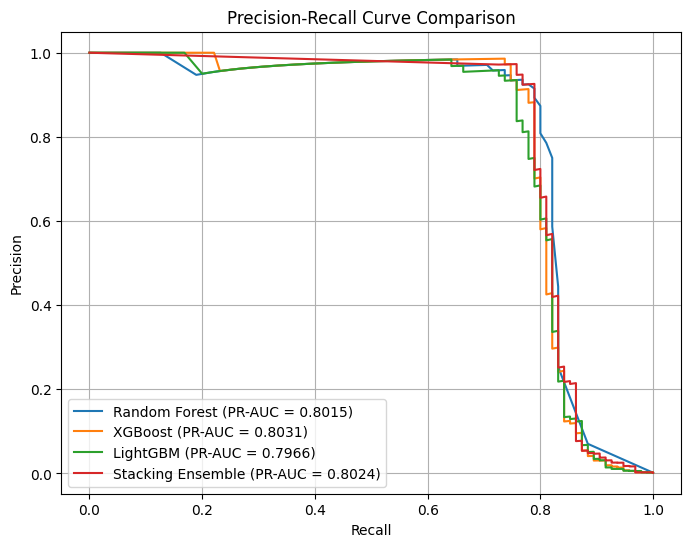

In [ ]:
# ============================================================
# PRECISION-RECALL CURVE COMPARISON
# ============================================================

from sklearn.metrics import precision_recall_curve

plt.figure(figsize=(8, 6))

for name, probabilities in model_probabilities.items():

    precision, recall, _ = precision_recall_curve(
        y_test,
        probabilities
    )

    pr_auc = average_precision_score(
        y_test,
        probabilities
    )

    plt.plot(
        recall,
        precision,
        label=f"{name} (PR-AUC = {pr_auc:.4f})"
    )

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve Comparison")
plt.legend()
plt.grid()
plt.show()

In [ ]:
fraud_analysis["Risk_Level"]

,Risk_Level
86568,LOW RISK
251557,LOW RISK
20232,LOW RISK
68952,LOW RISK
191852,LOW RISK
...,...
56516,LOW RISK
188431,LOW RISK
115561,LOW RISK
187644,LOW RISK


========== RISK LEVEL DISTRIBUTION ==========
Risk_Level
LOW RISK       56678
HIGH RISK         53
MEDIUM RISK       15
Name: count, dtype: int64


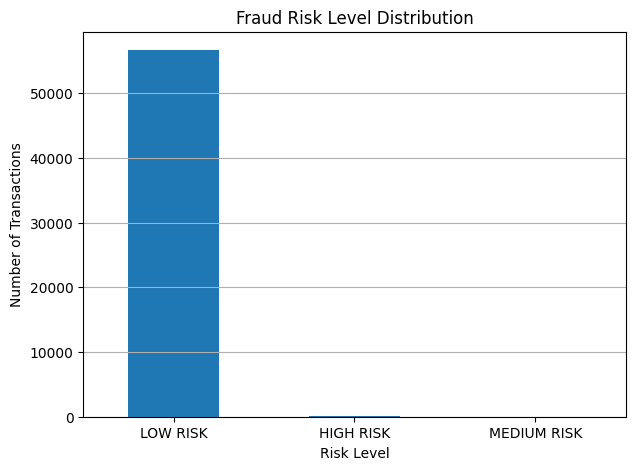

In [ ]:
# ============================================================
# RISK LEVEL DISTRIBUTION
# ============================================================

risk_counts = fraud_analysis["Risk_Level"].value_counts()

print("========== RISK LEVEL DISTRIBUTION ==========")
print(risk_counts)

plt.figure(figsize=(7, 5))

risk_counts.plot(
    kind="bar"
)

plt.xlabel("Risk Level")
plt.ylabel("Number of Transactions")
plt.title("Fraud Risk Level Distribution")
plt.xticks(rotation=0)
plt.grid(axis="y")
plt.show()

In [ ]:
# ============================================================
# FINAL RESULTS TABLE
# ============================================================

final_results = results.copy()

final_results["Accuracy"] = (
    final_results["Accuracy"] * 100
)

final_results["Precision"] = (
    final_results["Precision"] * 100
)

final_results["Recall"] = (
    final_results["Recall"] * 100
)

final_results["F1 Score"] = (
    final_results["F1 Score"] * 100
)

print("========== FINAL RESULTS (%) ==========")
print(
    final_results.round(2).to_string(index=False)
)

========== FINAL RESULTS (%) ==========
                   Model  Accuracy  Precision  Recall  F1 Score  ROC-AUC  PR-AUC
           Random Forest     99.94      97.01   68.42     80.25     0.94     0.8
                 XGBoost     99.93      80.65   78.95     79.79     0.97     0.8
                LightGBM     99.93      82.02   76.84     79.35     0.97     0.8
Stacking Ensemble (0.99)     99.87      56.93   82.11     67.24     0.97     0.8


In [ ]:
from scipy.stats import chi2_contingency

# Recreate time-based categories
df["Hour"] = (df["Time"] // 3600) % 24

def time_period(hour):
    if 6 <= hour < 12:
        return "Morning"
    elif 12 <= hour < 18:
        return "Afternoon"
    elif 18 <= hour < 24:
        return "Evening"
    else:
        return "Night"

df["Time_Period"] = df["Hour"].apply(time_period)

# Create contingency table
time_fraud_table = pd.crosstab(df["Time_Period"], df["Class"])

print("Contingency Table:")
display(time_fraud_table)

# Chi-square test
chi2, p_value, dof, expected = chi2_contingency(time_fraud_table)

print("Chi-square Statistic:", chi2)
print("p-value:", p_value)

if p_value < 0.05:
    print("Result: Significant association between Time Period and Fraud Occurrence.")
else:
    print("Result: No significant association between Time Period and Fraud Occurrence.")

Contingency Table:


Class,0,1
Time_Period,,
Afternoon,95988,133
Evening,93013,107
Morning,70525,118
Night,23727,115


Chi-square Statistic: 162.36973894524988
p-value: 5.645497577595202e-35
Result: Significant association between Time Period and Fraud Occurrence.


In [ ]:
from scipy.stats import mannwhitneyu

# Separate transaction amounts
genuine_amounts = df[df["Class"] == 0]["Amount"]
fraud_amounts = df[df["Class"] == 1]["Amount"]

# Mann-Whitney U test
u_statistic, p_value = mannwhitneyu(
    genuine_amounts,
    fraud_amounts,
    alternative="two-sided"
)

print("Mann-Whitney U Statistic:", u_statistic)
print("p-value:", p_value)

if p_value < 0.05:
    print("Result: Transaction amounts differ significantly between genuine and fraudulent transactions.")
else:
    print("Result: No significant difference in transaction amounts.")

Mann-Whitney U Statistic: 74461539.5
p-value: 2.68609023836721e-05
Result: Transaction amounts differ significantly between genuine and fraudulent transactions.


In [ ]:

import os
import joblib
import shutil
from google.colab import files

# Create folder
os.makedirs("fraud_model", exist_ok=True)

# Save trained model and required information
joblib.dump(best_model, "fraud_model/best_model.pkl")
joblib.dump(scaler, "fraud_model/scaler.pkl")
joblib.dump(best_threshold, "fraud_model/threshold.pkl")
joblib.dump(list(X_train.columns), "fraud_model/features.pkl")
joblib.dump(best_model_name, "fraud_model/model_name.pkl")
joblib.dump(results, "fraud_model/results.pkl")

# Create ZIP file
shutil.make_archive("fraud_model", "zip", "fraud_model")

# Download to laptop
files.download("fraud_model.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>